# MM HW 3

## Problem 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt

loaded_data = np.loadtxt("measurements.txt", delimiter='\t', skiprows=1)
x1,x2,x3,x4 = loaded_data.T

### Loading Data:

Text(0.5, 1.0, 'Observable4')

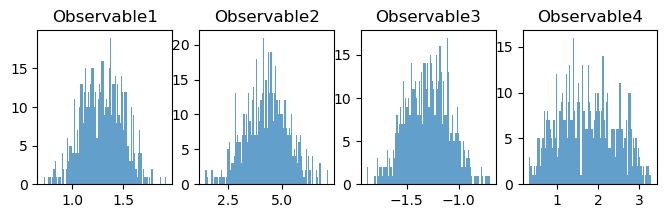

In [17]:
f = plt.figure(figsize=(8,2))
ax1, ax2, ax3, ax4 = plt.subplot(141), plt.subplot(142), plt.subplot(143), plt.subplot(144)

ax1.hist(x1, bins=100, alpha =0.7)
ax1.set_title("Observable1")

ax2.hist(x2, bins=100, alpha =0.7)
ax2.set_title("Observable2")

ax3.hist(x3, bins=100, alpha =0.7)
ax3.set_title("Observable3")

ax4.hist(x4, bins=100, alpha =0.7)
ax4.set_title("Observable4")

### Calculate Mean and Variance

There isn't a note this time that specifes we can't use the built in mean and variance methods in numpy so I am doing that.

In [31]:
# Means:
x1_mean = np.mean(x1)
x2_mean = np.mean(x2)
x3_mean = np.mean(x3)
x4_mean = np.mean(x4)

print(f" X1 Mean: {x1_mean}\n X2 Mean: {x2_mean}\n X3 Mean: {x3_mean}\n X4 Mean: {x4_mean}")

 X1 Mean: 1.2952197670373455
 X2 Mean: 4.306175028772326
 X3 Mean: -1.2962214060287103
 X4 Mean: 1.7300422632321302


In [32]:
# Variances:
x1_var = np.var(x1, ddof=1)
x2_var = np.var(x2, ddof=1)
x3_var = np.var(x3, ddof=1)
x4_var = np.var(x4, ddof=1)

print(f" X1 Var: {x1_var}\n X2 Var: {x2_var}\n X3 Var: {x3_var}\n X4 Var: {x4_var}")

 X1 Var: 0.04081891737678224
 X2 Var: 1.027517579673967
 X3 Var: 0.04488372300619627
 X4 Var: 0.4980981301803912


## Error Propogation

### f(x1, x2, x3) = x1*x2 - 3x3

df/dx1 = x2
df/dx2 = x1
df/dx3 = -3

In [24]:
N = len(x1)
print(N)

# Covariance:
x1_x2_cov = np.cov(x1, x2, ddof=1)[0,1]
x1_x3_cov = np.cov(x1, x3, ddof=1)[0,1]
x2_x3_cov = np.cov(x2, x3, ddof=1)[0,1]

print(f" X1 X2 Covariance: {x1_x2_cov}\n X1 X3 Covariance: {x1_x3_cov}\n X2 X3 Covariance: {x2_x3_cov}")

600
 X1 X2 Covariance: -0.008671022432662514
 X1 X3 Covariance: -0.04115846278342012
 X2 X3 Covariance: 0.007793151430957081


In [25]:
# Variance of the Means: 
x1_var_mean = x1_var / N
x2_var_mean = x2_var / N
x3_var_mean = x3_var / N 

print(f" X1 Mean Variance: {x1_var_mean}\n X2 Mean Variance: {x2_var_mean}\n X3 Mean Variance: {x3_var_mean}")


# Covariance of the Means:
x1_x2_mean_cov = x1_x2_cov / N
x1_x3_mean_cov = x1_x3_cov / N
x2_x3_mean_cov = x2_x3_cov / N

print(f" X1 X2 Mean Covariance: {x1_x2_mean_cov}\n X1 X3 Mean Covariance: {x1_x3_mean_cov}\n X2 X3 Mean Covariance: {x2_x3_mean_cov}")

 X1 Mean Variance: 6.803152896130374e-05
 X2 Mean Variance: 0.0017125292994566118
 X3 Mean Variance: 7.480620501032712e-05
 X1 X2 Mean Covariance: -1.4451704054437524e-05
 X1 X3 Mean Covariance: -6.859743797236686e-05
 X2 X3 Mean Covariance: 1.2988585718261801e-05


$$
\begin{aligned}
(\Delta f_a)^2 ={}&
\bar{x}_2^2 \operatorname{Var}(\bar{x}_1)
+\bar{x}_1^2 \operatorname{Var}(\bar{x}_2)
+9\operatorname{Var}(\bar{x}_3)\\
&+2\bar{x}_1\bar{x}_2\operatorname{Cov}(\bar{x}_1,\bar{x}_2)\\
&-6\bar{x}_2\operatorname{Cov}(\bar{x}_1,\bar{x}_3)\\
&-6\bar{x}_1\operatorname{Cov}(\bar{x}_2,\bar{x}_3)
\end{aligned}
$$

In [30]:
# Calculate Error:
delta_f_a_squared = (
    x2_mean**2 * x1_var_mean
    + x1_mean**2 * x2_var_mean
    + 9 * x3_var_mean
    + 2 * x1_mean * x2_mean * x1_x2_mean_cov
    - 6 * x2_mean * x1_x3_mean_cov
    - 6 * x1_mean * x2_x3_mean_cov
)

delta_f_a = np.sqrt(delta_f_a_squared)
print(f"Delta f (error): {delta_f_a}")

Delta f (error): 0.07948530326396337


### f(x1, x2, x3, x4) = ln(x4) + 2^(x1*x2) + x3^4

$$
\begin{aligned}
f(x_1,x_2,x_3,x_4)
&= \ln(x_4) + 2^{x_1x_2} + x_3^4
\end{aligned}
$$

$$
\begin{aligned}
\frac{\partial f}{\partial x_1}
&= 2^{x_1x_2}\ln(2)x_2 \\[6pt]
\frac{\partial f}{\partial x_2}
&= 2^{x_1x_2}\ln(2)x_1 \\[6pt]
\frac{\partial f}{\partial x_3}
&= 4x_3^3 \\[6pt]
\frac{\partial f}{\partial x_4}
&= \frac{1}{x_4}
\end{aligned}
$$

In [35]:
# New Mean Variance:
x4_var_mean = x4_var / N


# New Covariances:
x1_x4_cov = np.cov(x1, x4, ddof=1)[0,1]
x2_x4_cov = np.cov(x2, x4, ddof=1)[0,1]
x3_x4_cov = np.cov(x3, x4, ddof=1)[0,1]


# New Mean Covariance: 
x1_x4_mean_cov = x1_x4_cov / N
x2_x4_mean_cov = x2_x4_cov / N
x3_x4_mean_cov = x3_x4_cov / N


print(f" X4 Mean Variance: {x4_var_mean}\n X1 X4 Cov: {x1_x4_cov}\n X2 X4 Cov: {x2_x4_cov}\n X3 X4 Cov: {x3_x4_cov}\n X1 X4 Mean Cov: {x1_x4_mean_cov}\n X2 X4 Mean Cov: {x2_x4_mean_cov}\n X3 X4 Mean Cov: {x3_x4_mean_cov}")

 X4 Mean Variance: 0.0008301635503006519
 X1 X4 Cov: -0.007022847143528137
 X2 X4 Cov: -0.0012857290070457078
 X3 X4 Cov: 0.005342955254638921
 X1 X4 Mean Cov: -1.1704745239213561e-05
 X2 X4 Mean Cov: -2.142881678409513e-06
 X3 X4 Mean Cov: 8.904925424398201e-06


$$
\begin{aligned}
(\Delta f_b)^2 ={}&
\left(\frac{\partial f}{\partial x_1}\right)^2
\operatorname{Var}(\bar{x}_1)
+
\left(\frac{\partial f}{\partial x_2}\right)^2
\operatorname{Var}(\bar{x}_2)
+
\left(\frac{\partial f}{\partial x_3}\right)^2
\operatorname{Var}(\bar{x}_3)
+
\left(\frac{\partial f}{\partial x_4}\right)^2
\operatorname{Var}(\bar{x}_4)
\\[6pt]
&+
2\frac{\partial f}{\partial x_1}
\frac{\partial f}{\partial x_2}
\operatorname{Cov}(\bar{x}_1,\bar{x}_2)
\\[6pt]
&+
2\frac{\partial f}{\partial x_1}
\frac{\partial f}{\partial x_3}
\operatorname{Cov}(\bar{x}_1,\bar{x}_3)
\\[6pt]
&+
2\frac{\partial f}{\partial x_1}
\frac{\partial f}{\partial x_4}
\operatorname{Cov}(\bar{x}_1,\bar{x}_4)
\\[6pt]
&+
2\frac{\partial f}{\partial x_2}
\frac{\partial f}{\partial x_3}
\operatorname{Cov}(\bar{x}_2,\bar{x}_3)
\\[6pt]
&+
2\frac{\partial f}{\partial x_2}
\frac{\partial f}{\partial x_4}
\operatorname{Cov}(\bar{x}_2,\bar{x}_4)
\\[6pt]
&+
2\frac{\partial f}{\partial x_3}
\frac{\partial f}{\partial x_4}
\operatorname{Cov}(\bar{x}_3,\bar{x}_4)
\end{aligned}
$$

In [38]:
# Calculate Derivatives:
df_dx1 = 2**(x1_mean * x2_mean) * np.log(2) * x2_mean
df_dx2 = 2**(x1_mean * x2_mean) * np.log(2) * x1_mean
df_dx3 = 4 * x3_mean**3
df_dx4 = 1 / x4_mean


# Calculate Error:
delta_f_b_squared = (
    df_dx1**2 * x1_var_mean
    + df_dx2**2 * x2_var_mean
    + df_dx3**2 * x3_var_mean
    + df_dx4**2 * x4_var_mean
    
    + 2 * df_dx1 * df_dx2 * x1_x2_mean_cov
    + 2 * df_dx1 * df_dx3 * x1_x3_mean_cov
    + 2 * df_dx1 * df_dx4 * x1_x4_mean_cov
    + 2 * df_dx2 * df_dx3 * x2_x3_mean_cov
    + 2 * df_dx2 * df_dx4 * x2_x4_mean_cov
    + 2 * df_dx3 * df_dx4 * x3_x4_mean_cov
)


delta_f_a = np.sqrt(delta_f_a_squared)
print(f" Delta f (error): {delta_f_a}")

 Delta f (error): 0.07948530326396337


## Problem 2

In [39]:
loaded_data = np.loadtxt("Bobsmeasurements.txt", delimiter="\t", skiprows=1)
y = np.zeros(4, object)
y[0], y[1], y[2], y[3] = loaded_data.T

In [41]:
def count_within_distance(events, d):
    events = np.array(events)
    mean = np.mean(events)
    count = np.sum(np.abs(events-mean) <= d)
    return count / len(events)

Text(0.5, 1.0, 'Observable4')

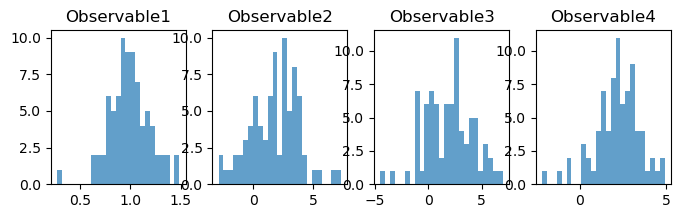

In [57]:
# Graphing the Data
f = plt.figure(figsize=(8,2))
ax1, ax2, ax3, ax4 = plt.subplot(141), plt.subplot(142), plt.subplot(143), plt.subplot(144)

ax1.hist(y[0], bins=25, alpha =0.7)
ax1.set_title("Observable1")

ax2.hist(y[1], bins=25, alpha =0.7)
ax2.set_title("Observable2")

ax3.hist(y[2], bins=25, alpha =0.7)
ax3.set_title("Observable3")

ax4.hist(y[3], bins=25, alpha =0.7)
ax4.set_title("Observable4")

In [56]:
# Calculating Means
y0_mean = np.mean(y[0])
y1_mean = np.mean(y[1])
y2_mean = np.mean(y[2])
y3_mean = np.mean(y[3])

print(f" Y0 Mean: {y0_mean}\n Y1 Mean: {y1_mean}\n Y2 Mean: {y2_mean}\n Y3 mean: {y3_mean}\n")

# Calculating Variances
y0_var = np.var(y[0], ddof=1)
y1_var = np.var(y[1], ddof=1)
y2_var = np.var(y[2], ddof=1)
y3_var = np.var(y[3], ddof=1)

print(f" Y0 Var: {y0_var}\n Y1 Var: {y1_var}\n Y2 Var: {y2_var}\n Y3 Var: {y3_var}\n")

# Calculating Covariances
y0_y1_cov = np.cov(y[0], y[1], ddof=1)[0,1]
y0_y2_cov = np.cov(y[0], y[2], ddof=1)[0,1]
y0_y3_cov = np.cov(y[0], y[3], ddof=1)[0,1]
y1_y2_cov = np.cov(y[1], y[2], ddof=1)[0,1]
y1_y3_cov = np.cov(y[1], y[3], ddof=1)[0,1]
y2_y3_cov = np.cov(y[2], y[3], ddof=1)[0,1]

print(f" Y0 Y1 Cov: {y0_y1_cov}\n Y0 Y2 Cov: {y0_y2_cov}\n Y0 Y3 Cov: {y0_y3_cov}\n Y1 Y2 Cov: {y1_y2_cov}\n Y1 Y3 Cov: {y1_y3_cov}\n Y2 Y3 Cov: {y2_y3_cov}")

 Y0 Mean: 0.9921653521539462
 Y1 Mean: 1.811406644854729
 Y2 Mean: 1.9443967723789641
 Y3 mean: 2.167566229567627

 Y0 Var: 0.04073972356663425
 Y1 Var: 4.007130049080217
 Y2 Var: 4.99688334652459
 Y3 Var: 1.6701690681551664

 Y0 Y1 Cov: -0.008439983043518482
 Y0 Y2 Cov: -0.009907727107730876
 Y0 Y3 Cov: 0.029023697970546034
 Y1 Y2 Cov: 0.235898274677089
 Y1 Y3 Cov: 0.14471771458220814
 Y2 Y3 Cov: -0.13728563152952322


Ok time to setup the inequality. I think I already see what's wrong with the data, but still I think I see how the inequality is going to show definitively that it's wrong. Based on the graphs of the distributions I believe I should be able to use the unimodol inequality for an even deeper accuracy. 

The CWD function allows us to model this with a specified d, where d should be the "k*delta" limit from the class notes. So first, I need to calculate the standard deviations and then start applying the k values to see what fraction of values are present per k std's.

I hope this makes sense.

In [61]:
# Standard deviations:
y0_std = np.sqrt(y0_var)
y1_std = np.sqrt(y1_var)
y2_std = np.sqrt(y2_var)
y3_std = np.sqrt(y3_var)

###########################

y0_d = y0_std * 2 # 2 STD
y0_fraction = count_within_distance(y[0], y0_d)
print(f"Y0-2-STD: {y0_fraction}")

y1_d = y1_std * 2 # 2 STD
y1_fraction = count_within_distance(y[1], y1_d)
print(f"Y1-2-STD: {y1_fraction}")

y2_d = y2_std * 2 # 2 STD
y2_fraction = count_within_distance(y[2], y2_d)
print(f"Y2-2-STD: {y2_fraction}")

y3_d = y3_std * 2 # 2 STD
y3_fraction = count_within_distance(y[3], y3_d)
print(f"Y3-2-STD: {y3_fraction}")

# Unimodol inequality at 2 STD
um_bound = 1 - 4/(9*2**2)
print(f"Unimodol Minimum (2-STD): {um_bound}")

Y0-2-STD: 0.9625
Y1-2-STD: 0.95
Y2-2-STD: 0.9625
Y3-2-STD: 0.925
Unimodol Minimum (2-STD): 0.8888888888888888


So this inequality held true.

In [62]:
y0_d = y0_std * 3 # 3 STD
y0_fraction = count_within_distance(y[0], y0_d)
print(f"Y0-2-STD: {y0_fraction}")

y1_d = y1_std * 3 # 3 STD
y1_fraction = count_within_distance(y[1], y1_d)
print(f"Y1-2-STD: {y1_fraction}")

y2_d = y2_std * 3 # 3 STD
y2_fraction = count_within_distance(y[2], y2_d)
print(f"Y2-2-STD: {y2_fraction}")

y3_d = y3_std * 3 # 3 STD
y3_fraction = count_within_distance(y[3], y3_d)
print(f"Y3-2-STD: {y3_fraction}")

# Unimodol inequality at 3 STD
um_bound = 1 - 4/(9*3**2)
print(f"Unimodol Minimum (3-STD): {um_bound}")

Y0-2-STD: 0.9875
Y1-2-STD: 1.0
Y2-2-STD: 1.0
Y3-2-STD: 0.9875
Unimodol Minimum (3-STD): 0.9506172839506173


This inequality held true. So I believe I understand what to do since I know IM right at least.

### Testing Bob's Numbers:

In [63]:
# Standard deviations (from assignment):
y0_std = .208
y1_std = .300
y2_std = .350
y3_std = .950

###########################

y0_d = y0_std * 2 # 2 STD
y0_fraction = count_within_distance(y[0], y0_d)
print(f"Y0-2-STD: {y0_fraction}")

y1_d = y1_std * 2 # 2 STD
y1_fraction = count_within_distance(y[1], y1_d)
print(f"Y1-2-STD: {y1_fraction}")

y2_d = y2_std * 2 # 2 STD
y2_fraction = count_within_distance(y[2], y2_d)
print(f"Y2-2-STD: {y2_fraction}")

y3_d = y3_std * 2 # 2 STD
y3_fraction = count_within_distance(y[3], y3_d)
print(f"Y3-2-STD: {y3_fraction}")

# Unimodol inequality at 2 STD
um_bound = 1 - 4/(9*2**2)
print(f"Unimodol Minimum (2-STD): {um_bound}")

Y0-2-STD: 0.9625
Y1-2-STD: 0.2125
Y2-2-STD: 0.2625
Y3-2-STD: 0.8625
Unimodol Minimum (2-STD): 0.8888888888888888


Woahhhhhh Bobby boy, slow your role.

In [64]:
y0_d = y0_std * 3 # 3 STD
y0_fraction = count_within_distance(y[0], y0_d)
print(f"Y0-2-STD: {y0_fraction}")

y1_d = y1_std * 3 # 3 STD
y1_fraction = count_within_distance(y[1], y1_d)
print(f"Y1-2-STD: {y1_fraction}")

y2_d = y2_std * 3 # 3 STD
y2_fraction = count_within_distance(y[2], y2_d)
print(f"Y2-2-STD: {y2_fraction}")

y3_d = y3_std * 3 # 3 STD
y3_fraction = count_within_distance(y[3], y3_d)
print(f"Y3-2-STD: {y3_fraction}")

# Unimodol inequality at 3 STD
um_bound = 1 - 4/(9*3**2)
print(f"Unimodol Minimum (3-STD): {um_bound}")

Y0-2-STD: 0.9875
Y1-2-STD: 0.2875
Y2-2-STD: 0.325
Y3-2-STD: 0.975
Unimodol Minimum (3-STD): 0.9506172839506173


**Ok so what we did find out is that for certain Bob's Y1 and Y2 are most certainly not correct variances since they do not comply with the inequality.
I had proved this already by correctly solving for mean and variance, but the inequality showed that instead of needing to write all that code to do that we could simply use
the inequality to show that while the sample data graphically/visually looks unimodol, the variances do not indicate that, by quite a large margin. Meanwhile the correctly calculated variances ceratainly do.**